# Quickstart

In [1]:
import os
os.environ.setdefault("MUJOCO_GL", "egl")  # headless rendering; use "glfw" on a desktop

import time
import numpy as np
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import warp as wp

wp.config.log_level = wp.LOG_WARNING  # no init banner
wp.init()
print("device:", wp.get_device())

device: cuda:0


In [2]:
class Camera:
    """Draws one world of a Lodos `Sim` the way MuJoCo would: the MJCF's geoms at that world's `qpos`."""

    def __init__(self, sim, height=360, width=480, distance=8.0, azimuth=135.0, elevation=-20.0, lookat=(0, 0, 1)):
        self.model = sim.mjm
        self.model.vis.headlight.ambient[:] = 0.35
        self.model.vis.headlight.diffuse[:] = 0.6
        self.data = mujoco.MjData(self.model)
        self.renderer = mujoco.Renderer(self.model, height, width)
        self.cam = mujoco.MjvCamera()
        self.cam.distance, self.cam.azimuth, self.cam.elevation = distance, azimuth, elevation
        self.cam.lookat[:] = lookat

    def __call__(self, qpos):
        self.data.qpos[:] = qpos
        mujoco.mj_kinematics(self.model, self.data)
        self.renderer.update_scene(self.data, camera=self.cam)
        return self.renderer.render()

## Creating a batch of worlds

The function `viewer.scenes.armadillo.build` creates the five-armadillo drop scene, with every world from its own random
stack. It returns a `lodos.sim.Sim` object, which internally stores: the MuJoCo model (`sim.mjm`), the rigid-body state
(`sim.drbd`), Lodos's collision context (`sim.mcol`, `sim.dcol`), model and data objects that store the scene specification and runtime configuration
(`sim.m`, `sim.d`) and the solver object (`sim.solver`, its options resolved in `sim.options`), all for
`sim.B` worlds.

In [3]:
from lodos import step
from viewer.scenes import armadillo

sim = armadillo.build(batch=64, seed=0, nconmax=256, njmax=1024)
print(sim)
print("qpos per world:", sim.drbd.qpos.shape, " dt:", sim.mjm.opt.timestep)
print("the solver's options:", sim.options)

Sim(B=64, lodos pairs=25)
qpos per world: (64, 35)  dt: 0.002
the solver's options: {'mode': 'exact', 'prox_rho': 1.0, 'prox_iters_per_qp': 10, 'prox_tol_z': 0.001, 'prox_tol_sigma': 0.001, 'baumgarte': True, 'baumgarte_alpha': 0.1, 'baumgarte_slop': 0.0002, 'de_saxce': True, 'refresh_de_saxce_per_prox': True, 'warm_start': True, 'fused_newton': False, 'groups': None, 'normal_bins': 1, 'moment_bins': 1, 'row_space': False, 'shared_hessian': False}


## Time stepping

`step.make_step_graph(sim)` captures one whole step -- kinematics, collision, the contact
solve, integration -- as a CUDA graph and returns a function that replays it. Each call
advances every world by `dt`. Every tenth step the loop below also reads the contact count
(`sim.d.nacon`, over the batch) and the most rows any world has (`sim.d.nefc`), to check them
against their capacities; as well as overflow flags (`sim.dcol.overflow`).

In [4]:
replay = step.make_step_graph(sim)
cam = Camera(sim, distance=9.0, lookat=(0, 0, 1.5))

frames, heights, peak = [], [], np.zeros(2, int)
t0 = time.perf_counter()
for i in range(1500):  # 3 s
    replay()
    if i % 10 == 0:
        q = sim.drbd.qpos.numpy()
        heights.append(q[:, 2::7].copy())  # each body's z, every world
        frames.append(cam(q[0]))
        peak = np.maximum(peak, (sim.d.nacon.numpy()[0], sim.d.nefc.numpy().max()))
wp.synchronize()
print(f"{1500 * sim.B / (time.perf_counter() - t0):,.0f} world-steps/s, rendering included")
print(f"Contacts at most {peak[0]} of {sim.d.naconmax}, rows at most {peak[1]} of {sim.d.njmax} a world; "
      f"collision overflowed: {bool(sim.dcol.overflow.numpy().any())}")
media.show_video(frames, fps=50)

33,691 world-steps/s, rendering included
Contacts at most 653 of 16384, rows at most 51 of 1024 a world; collision overflowed: False


This browser does not support the video tag.


`qpos` holds 7 numbers per free body -- position, then a quaternion -- so `q[:, 2::7]` is
every body's height. Over the batch:

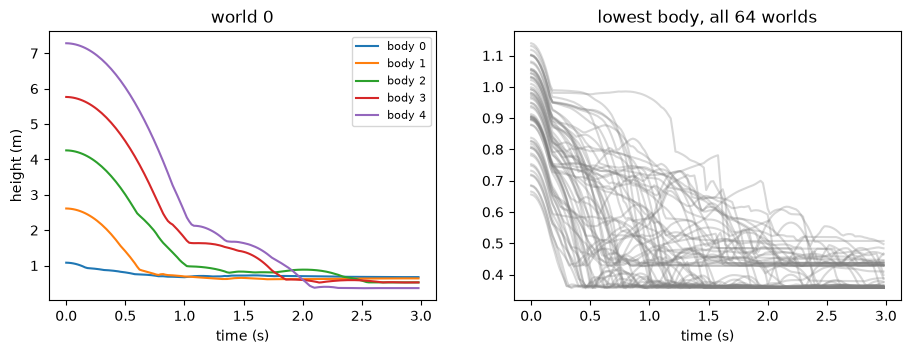

In [5]:
heights = np.array(heights)  # (frames, worlds, bodies)
t = np.arange(len(heights)) * 10 * sim.mjm.opt.timestep
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for b in range(heights.shape[2]):
    ax[0].plot(t, heights[:, 0, b], label=f"body {b}")
ax[0].set(title="world 0", xlabel="time (s)", ylabel="height (m)")
ax[0].legend(fontsize=8)
ax[1].plot(t, heights.min(axis=2), color="tab:gray", alpha=0.3)
ax[1].set(title="lowest body, all 64 worlds", xlabel="time (s)")
plt.show()

## Inspecting contacts

Lodos's collision writes its contacts in `sim.dcol`: with `dcol.ct[2]` of them this step, each with
its world (`b_nCa3`), point (`p_nCa3`), normal (`n_nCa3`) and depth (`sdf_nCa3`, negative
inside). The solve appends them to the contact buffer of the scene configuration, `sim.d.contact`, after contacts from the GJK+EPA pipeline (none here: every body is a Lodos surface), and writes their constraint forces in
`sim.d.efc.force`. `lodos.cd.solver.constraint.contact_force` decodes a contact's force in its
own frame: the normal force first, then the friction. The generalized constraint force is
`sim.d.qfrc_constraint`. Below, the contact buffer holds only contacts from Lodos surfaces, and no contact's
friction exceeds `mu` times its normal force: those at 0.8 are on the cone's edge, sliding.

In [6]:
from lodos.cd.solver import constraint as solver_constraint

n = int(sim.dcol.ct.numpy()[2])
world = sim.dcol.b_nCa3.numpy()[:n]
depth = -sim.dcol.sdf_nCa3.numpy()[:n]
print(f"Lodos's collision: {n} contacts in {len(np.unique(world))} worlds, {n / sim.B:.1f} a world; "
      f"depth mean {depth.mean() * 1e3:.3f} mm, max {depth.max() * 1e3:.3f} mm")

nacon = int(sim.d.nacon.numpy()[0])
force = wp.zeros(nacon, dtype=wp.spatial_vector)
solver_constraint.contact_force(sim.m, sim.d, wp.array(np.arange(nacon, dtype=np.int32)), False, force)
f = force.numpy()[:, :3]  # in each contact's frame: the normal force, then the two friction directions
fn, ft = f[:, 0], np.linalg.norm(f[:, 1:], axis=1)
ratio = ft / np.maximum(fn, 1e-9)
print(f"Contact buffer: {nacon} contacts")
print(f"friction / normal force: median {np.median(ratio):.3f}, max {ratio.max():.3f} (mu = 0.8)")

Lodos's collision: 651 contacts in 64 worlds, 10.2 a world; depth mean 0.164 mm, max 1.703 mm
Contact buffer: 651 contacts
friction / normal force: median 0.347, max 0.800 (mu = 0.8)
